# PHÂN TÍCH KHÁM PHÁ VÀ TIỀN XỬ LÝ DỮ LIỆU WINE

**Mục tiêu phân tích**

Đánh giá cấu trúc, chất lượng và đặc điểm phân bố của dữ liệu; xây dựng biểu diễn hai chiều bằng PCA từ các thuộc tính hóa học liên tục. Báo cáo tập trung vào hai nội dung: **(1) đọc dữ liệu và khám phá; (2) tạo dữ liệu mới và trực quan hóa**.

**Phương pháp**

Tìm tệp Excel → chuyển sang CSV → chia train/test → xác nhận cấu trúc và kiểm tra chất lượng từng tập → thống kê mô tả trên train → chuẩn hóa và PCA (fit trên train, transform test) → lưu riêng dữ liệu từng bước và biểu đồ.

Nhãn chỉ được sử dụng để mô tả phân bố lớp và tô màu biểu đồ; không tham gia tính toán chuẩn hóa hoặc PCA. Các bảng, chỉ số và nhận xét định lượng được tính lại trực tiếp từ dữ liệu khi chạy notebook.

## Thiết lập phân tích

Notebook tự tìm thư mục dự án từ thư mục làm việc hiện tại hoặc các thư mục cha thông qua `datasets/raw`. Tệp Excel được chuyển thành CSV trước khi đọc. Không sử dụng đường dẫn tuyệt đối cố định.

Dữ liệu được chia train/test 80/20 có phân tầng theo nhãn trước khi tiền xử lý. Thống kê khám phá và các tham số tiền xử lý được xác định từ train; test chỉ áp dụng các phép biến đổi đã fit trên train.

Các tệp CSV của từng bước được lưu riêng trong **`datasets/output`**; biểu đồ PNG lưu trong **`output` ở gốc dự án**. Hai thư mục này phải có sẵn như cấu trúc dự án. Chạy lại sẽ cập nhật các tệp cùng tên do notebook tạo, không xóa các tệp khác.

Môi trường cần có `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `ipykernel`, `openpyxl`. Chạy các cell từ đầu để tái lập toàn bộ kết quả.

In [ ]:
from pathlib import Path
import re
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

EXCEL_SHEET = "wine.data"
TARGET = "class"
TEST_SIZE = 0.20
RANDOM_STATE = 42

plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
pd.set_option("display.max_columns", 20)
print("Môi trường:", "Python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__)

Môi trường: Python 3.12.4 | pandas 2.2.2 | numpy 1.26.4 | scikit-learn 1.4.2 | matplotlib 3.8.4


In [2]:
# Tìm gốc dự án và các thư mục đã có
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in [current_dir, *current_dir.parents]
     if (folder / "datasets" / "raw").is_dir()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy datasets/raw. Mở notebook từ dự án hoặc một thư mục con.")

DATA_DIR = PROJECT_ROOT / "datasets" / "raw"

# CSV và biểu đồ cùng lưu trong datasets/output 
OUTPUT_DIR = PROJECT_ROOT / "datasets" / "output"
FIGURE_DIR = OUTPUT_DIR

# Giữ nguyên thư mục và các file hiện có; chỉ tạo nếu chưa tồn tại.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for directory in (OUTPUT_DIR, FIGURE_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Thiếu thư mục đầu ra theo cấu trúc dự án: {directory}")

xlsx_files = sorted(p for p in DATA_DIR.glob("*.xlsx") if not p.name.startswith("~$"))
if not xlsx_files:
    raise FileNotFoundError(f"Không có tệp Excel trong {DATA_DIR}")
if len(xlsx_files) > 1:
    raise ValueError("Có nhiều tệp Excel; cần xác định nguồn dữ liệu: " + ", ".join(p.name for p in xlsx_files))
xlsx_path = xlsx_files[0]

# Mỗi bảng được lưu vào một tệp riêng ngay tại bước tạo bảng.
saved_files = []
def save_table(table, filename, index=False):
    destination = OUTPUT_DIR / filename
    table.to_csv(destination, index=index, encoding="utf-8-sig")
    saved_files.append({"Tệp": filename, "Số dòng": len(table), "Thư mục": "datasets/output"})
    return destination

print("Excel nguồn:", xlsx_path)
print("CSV đầu ra:", OUTPUT_DIR)
print("Biểu đồ:", FIGURE_DIR)

Excel nguồn: D:\k1_nam3\data_mining\data_mining\datasets\raw\D00 - wine.data.xlsx
CSV đầu ra: D:\k1_nam3\data_mining\data_mining\datasets\output
Biểu đồ: D:\k1_nam3\data_mining\data_mining\datasets\output


## 1. Đọc dữ liệu và khám phá
### 1.1. Nguồn dữ liệu và cấu trúc thuộc tính

Đọc trực tiếp tệp nguồn, bảo toàn dữ liệu ban đầu trong `df_raw`. Chuẩn hóa tên cột nhằm bảo đảm thao tác nhất quán; giữ nguyên ý nghĩa và giá trị của các thuộc tính. Cấu trúc kỳ vọng được kiểm tra theo tên thay vì gán lại tên theo vị trí cột.

In [7]:
# Chuyển XLSX thành CSV, sau đó đọc CSV vào bộ nhớ.
with pd.ExcelFile(xlsx_path, engine="openpyxl") as workbook:
    if EXCEL_SHEET not in workbook.sheet_names:
        raise ValueError(f"Không có sheet {EXCEL_SHEET!r}. Các sheet hiện có: {workbook.sheet_names}")
    df_excel = pd.read_excel(workbook, sheet_name=EXCEL_SHEET)
if df_excel.empty:
    raise ValueError("Sheet dữ liệu không chứa bản ghi.")

csv_path = save_table(df_excel, "00_wine_from_xlsx.csv")
df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
print("CSV đã chuyển từ Excel:", csv_path)
print("Kích thước dữ liệu nguồn:", df_raw.shape)
display(df_raw.head())

CSV đã chuyển từ Excel: D:\k1_nam3\data_mining\data_mining\datasets\output\00_wine_from_xlsx.csv
Kích thước dữ liệu nguồn: (178, 14)


,Class,1) Alcohol,2) Malic acid,3) Ash,4) Alcalinity of ash,5) Magnesium,6) Total phenols,7) Flavanoids,8) Nonflavanoid phenols,9) Proanthocyanins,10)Color intensity,11)Hue,12)OD280/OD315 of diluted wines,13)Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


### Chia dữ liệu trước tiền xử lý

Chia 80% train và 20% test, phân tầng theo nhãn, với seed cố định. Chỉ kiểm tra nhãn tối thiểu để thực hiện phép chia; chưa chuẩn hóa, tính ngưỡng ngoại lai hoặc fit PCA. Lưu riêng `train_data.csv`, `test_data.csv` với các cột và giá trị gốc. `01_split_membership.csv` ghi lại chỉ số dòng nguồn để truy vết. Các phân tích khám phá phía sau dùng train.

In [8]:
label_columns = [col for col in df_raw.columns if str(col).strip().lower() == TARGET]
if len(label_columns) != 1:
    raise ValueError("Cần đúng một cột nhãn Class để chia phân tầng.")
raw_target = label_columns[0]
if df_raw[raw_target].isna().any():
    raise ValueError("Có nhãn thiếu; cần kiểm tra nguồn trước khi chia dữ liệu.")

train_raw, test_raw = train_test_split(
    df_raw, test_size=TEST_SIZE, stratify=df_raw[raw_target], random_state=RANDOM_STATE
)
assert set(train_raw.index).isdisjoint(test_raw.index)
assert len(train_raw) + len(test_raw) == len(df_raw)
save_table(train_raw, "train_data.csv")
save_table(test_raw, "test_data.csv")
membership = pd.concat([
    pd.DataFrame({"source_row_index": train_raw.index, "split": "train"}),
    pd.DataFrame({"source_row_index": test_raw.index, "split": "test"})
], ignore_index=True).sort_values("source_row_index")
save_table(membership, "01_split_membership.csv")
display(pd.DataFrame({"Train": train_raw[raw_target].value_counts(),
                      "Test": test_raw[raw_target].value_counts()}).sort_index())
print(f"Train: {train_raw.shape}; Test: {test_raw.shape}")

,Train,Test
Class,,
1,47,12
2,57,14
3,38,10


Train: (142, 14); Test: (36, 14)


In [9]:
def clean_column_name(name):
    name = re.sub(r"^\d+\)\s*", "", str(name).strip())
    return re.sub(r"\s+", "_", name.lower().replace("/", "_"))

FEATURES = ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
            "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
            "color_intensity", "hue", "od280_od315_of_diluted_wines", "proline"]
train_named = train_raw.rename(columns=clean_column_name).copy()
test_named = test_raw.rename(columns=clean_column_name).copy()
df = train_named  # EDA chỉ dùng train.
if df.columns.duplicated().any():
    raise ValueError("Tên cột bị trùng sau chuẩn hóa.")
expected = {"class", *FEATURES}
if set(df.columns) != expected:
    raise ValueError(f"Sai cấu trúc. Thiếu: {expected - set(df.columns)}; thừa: {set(df.columns) - expected}")
display(pd.DataFrame({"Tên gốc": df_raw.columns, "Tên chuẩn hóa": df.columns}))
save_table(train_named, "02_train_columns_cleaned.csv")
save_table(test_named, "02_test_columns_cleaned.csv")

,Tên gốc,Tên chuẩn hóa
0,Class,class
1,1) Alcohol,alcohol
2,2) Malic acid,malic_acid
3,3) Ash,ash
4,4) Alcalinity of ash,alcalinity_of_ash
5,5) Magnesium,magnesium
6,6) Total phenols,total_phenols
7,7) Flavanoids,flavanoids
8,8) Nonflavanoid phenols,nonflavanoid_phenols
9,9) Proanthocyanins,proanthocyanins


WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/02_test_columns_cleaned.csv')

### 1.2. Quy mô, kiểu dữ liệu và phân bố nhãn

Phân biệt **kích thước bảng** (số mẫu × tổng số cột), **số chiều đặc trưng** (không tính nhãn) và **số trục DataFrame** (`ndim`). Kiểu lưu trữ số nguyên không đồng nghĩa với biến phân loại: Magnesium và Proline vẫn là các đại lượng đo được đưa vào phân tích liên tục.

Các thống kê trong mục này và các biểu đồ khám phá phía sau được tính trên tập train.

In [10]:
display(pd.DataFrame({"Thông tin": ["Số mẫu", "Tổng số cột", "Số đặc trưng", "Số cột nhãn", "Số trục DataFrame"],
                      "Giá trị": [len(df), df.shape[1], len(FEATURES), 1, df.ndim]}))
display(pd.DataFrame({"Kiểu dữ liệu": df.dtypes.astype(str), "Số giá trị có dữ liệu": df.notna().sum()}))
df.info()
label_counts = df["class"].value_counts(dropna=False).sort_index()
display(label_counts.rename("Số mẫu").to_frame().assign(Ty_le_phan_tram=lambda t: (100*t["Số mẫu"]/len(df)).round(2)))
save_table(df.dtypes.astype(str).rename("dtype").to_frame(), "03_train_dtypes.csv", index=True)
save_table(label_counts.rename("count").to_frame(), "03_train_class_counts.csv", index=True)

,Thông tin,Giá trị
0,Số mẫu,142
1,Tổng số cột,14
2,Số đặc trưng,13
3,Số cột nhãn,1
4,Số trục DataFrame,2


,Kiểu dữ liệu,Số giá trị có dữ liệu
class,int64,142
alcohol,float64,142
malic_acid,float64,142
ash,float64,142
alcalinity_of_ash,float64,142
magnesium,int64,142
total_phenols,float64,142
flavanoids,float64,142
nonflavanoid_phenols,float64,142
proanthocyanins,float64,142


<class 'pandas.core.frame.DataFrame'>
Index: 142 entries, 36 to 131
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         142 non-null    int64  
 1   alcohol                       142 non-null    float64
 2   malic_acid                    142 non-null    float64
 3   ash                           142 non-null    float64
 4   alcalinity_of_ash             142 non-null    float64
 5   magnesium                     142 non-null    int64  
 6   total_phenols                 142 non-null    float64
 7   flavanoids                    142 non-null    float64
 8   nonflavanoid_phenols          142 non-null    float64
 9   proanthocyanins               142 non-null    float64
 10  color_intensity               142 non-null    float64
 11  hue                           142 non-null    float64
 12  od280_od315_of_diluted_wines  142 non-null    float64
 13  proline  

,Số mẫu,Ty_le_phan_tram
class,,
1,47,33.10
2,57,40.14
3,38,26.76


WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/03_train_class_counts.csv')

### 1.3. Kiểm soát chất lượng và thống kê mô tả

Kiểm tra giá trị thiếu, giá trị không chuyển được sang số, vô hạn, nhãn ngoài miền và bản ghi trùng hoàn toàn. Nếu phát hiện dữ liệu không hợp lệ, quy trình dừng để xác minh nguồn; không tự ý điền khuyết hoặc sửa giá trị. Các bản ghi trùng hoàn toàn được loại riêng trong từng tập và ghi nhận số lượng. Nếu cùng một bản ghi xuất hiện ở cả train và test, quy trình dừng để tránh chồng lấn giữa hai tập.

Bảng thống kê báo cáo **Min, Max, Mean** theo yêu cầu, bổ sung độ lệch chuẩn và trung vị. Nhãn phân loại không được đưa vào bảng thống kê thuộc tính liên tục.

In [11]:
def check_and_clean(frame, split_name):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    invalid_numeric = frame.notna() & numeric.isna()
    report = pd.DataFrame({"Thiếu": frame.isna().sum(), "Không phải số": invalid_numeric.sum(),
        "Vô hạn": pd.Series(np.isinf(numeric.to_numpy(dtype=float)).sum(axis=0), index=frame.columns)})
    save_table(report, f"03_{split_name}_quality.csv", index=True)
    if report.to_numpy().sum() != 0:
        raise ValueError(f"Tập {split_name} có giá trị thiếu/không phải số/vô hạn. Kiểm tra nguồn trước khi tiếp tục.")
    if not numeric[TARGET].isin([1, 2, 3]).all():
        raise ValueError(f"Nhãn của tập {split_name} phải thuộc {{1, 2, 3}}.")
    duplicates = int(numeric.duplicated().sum())
    cleaned = numeric.drop_duplicates().copy()
    cleaned[TARGET] = cleaned[TARGET].astype(int)
    save_table(cleaned, f"04_{split_name}_clean.csv")
    return cleaned, report, duplicates

train_clean, quality, duplicate_count = check_and_clean(train_named, "train")
test_clean, test_quality, test_duplicate_count = check_and_clean(test_named, "test")
overlap = train_clean.merge(test_clean, how="inner", on=[TARGET, *FEATURES])
if not overlap.empty:
    raise ValueError("Có bản ghi trùng giữa train và test. Cần chia lại theo nhóm bản ghi để tránh rò rỉ.")

df_clean = train_clean  # Giữ các phân tích khám phá hiện có trên train.
display(quality)
print(f"Train sau làm sạch: {train_clean.shape}; bỏ {duplicate_count} dòng trùng.")
print(f"Test sau làm sạch: {test_clean.shape}; bỏ {test_duplicate_count} dòng trùng.")
stats = df_clean[FEATURES].agg(["min", "max", "mean", "std", "median"]).T
display(stats.round(3))
save_table(stats, "05_train_descriptive_statistics.csv", index=True)

X_train, y_train = train_clean[FEATURES].copy(), train_clean[TARGET].copy()
X_test, y_test = test_clean[FEATURES].copy(), test_clean[TARGET].copy()
save_table(X_train, "05_X_train_raw.csv")
save_table(X_test, "05_X_test_raw.csv")
save_table(y_train.to_frame(), "y_train.csv")
save_table(y_test.to_frame(), "y_test.csv")
save_table(pd.DataFrame({"source_row_index": X_train.index}), "05_train_row_order.csv")
save_table(pd.DataFrame({"source_row_index": X_test.index}), "05_test_row_order.csv")

,Thiếu,Không phải số,Vô hạn
class,0,0,0
alcohol,0,0,0
malic_acid,0,0,0
ash,0,0,0
alcalinity_of_ash,0,0,0
magnesium,0,0,0
total_phenols,0,0,0
flavanoids,0,0,0
nonflavanoid_phenols,0,0,0
proanthocyanins,0,0,0


Train sau làm sạch: (142, 14); bỏ 0 dòng trùng.
Test sau làm sạch: (36, 14); bỏ 0 dòng trùng.


,min,max,mean,std,median
alcohol,11.03,14.83,12.971,0.803,13.010
malic_acid,0.74,5.80,2.340,1.101,1.810
ash,1.36,3.22,2.365,0.268,2.360
alcalinity_of_ash,10.60,30.00,19.625,3.381,19.500
magnesium,70.00,162.00,99.634,14.937,97.000
total_phenols,0.98,3.88,2.274,0.621,2.335
flavanoids,0.34,3.74,1.985,0.952,2.135
nonflavanoid_phenols,0.13,0.63,0.360,0.119,0.340
proanthocyanins,0.42,3.58,1.600,0.580,1.560
color_intensity,1.28,13.00,4.990,2.335,4.640


WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/05_test_row_order.csv')

In [12]:
display(Markdown(
    f"**Đánh giá chất lượng dữ liệu.** Tệp nguồn có **{len(df_raw):,} bản ghi** và **{df_raw.shape[1]} cột**. "
    f"Kiểm tra trên tập train ghi nhận **{int(quality['Thiếu'].sum())} giá trị thiếu**, "
    f"**{int(quality['Không phải số'].sum())} giá trị không hợp lệ về kiểu số**, "
    f"**{int(quality['Vô hạn'].sum())} giá trị vô hạn** và **{duplicate_count} bản ghi trùng hoàn toàn**. "
    f"Sau xử lý, tập train dùng để phân tích có **{len(df_clean):,} bản ghi**, **{len(FEATURES)} đặc trưng** "
    f"và **{df_clean[TARGET].nunique()} lớp**. Test được xử lý và lưu riêng; không thực hiện điền khuyết hoặc thay thế giá trị."
))

**Đánh giá chất lượng dữ liệu.** Tệp nguồn có **178 bản ghi** và **14 cột**. Kiểm tra trên tập train ghi nhận **0 giá trị thiếu**, **0 giá trị không hợp lệ về kiểu số**, **0 giá trị vô hạn** và **0 bản ghi trùng hoàn toàn**. Sau xử lý, tập train dùng để phân tích có **142 bản ghi**, **13 đặc trưng** và **3 lớp**. Test được xử lý và lưu riêng; không thực hiện điền khuyết hoặc thay thế giá trị.

### 1.4. Cơ cấu các lớp

Phân bố nhãn cho biết mức độ đại diện của từng lớp trong tập dữ liệu. Số lượng và tỷ trọng được báo cáo trước khi diễn giải sự phân tách giữa các lớp trên không gian đặc trưng.

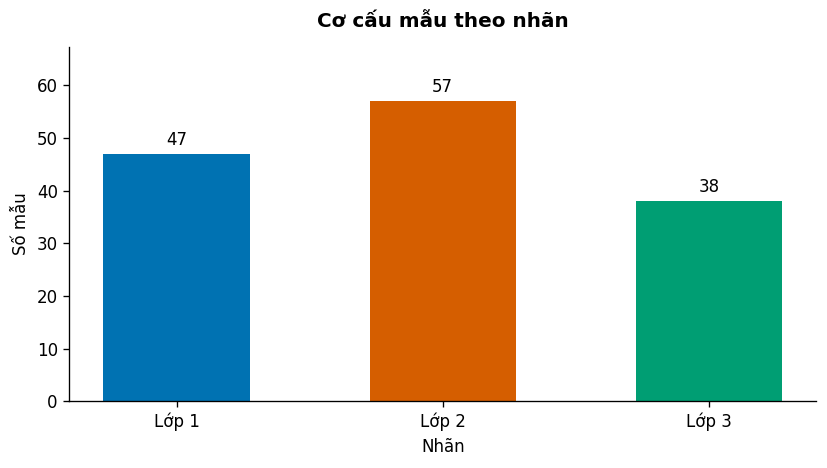

**Phân tích.** lớp 1: 47 mẫu (33.10%); lớp 2: 57 mẫu (40.14%); lớp 3: 38 mẫu (26.76%). Tỷ lệ số mẫu giữa lớp lớn nhất và nhỏ nhất là **1.50 lần**. Khi đọc các biểu đồ theo lớp, cần phân biệt mật độ điểm do quy mô mẫu với mức độ phân tán thực tế của thuộc tính.

In [13]:
classes = sorted(df_clean[TARGET].unique())
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]
CLASS_COLORS = {k: palette[i % len(palette)] for i, k in enumerate(classes)}
counts = df_clean[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([f"Lớp {k}" for k in counts.index], counts.values,
              color=[CLASS_COLORS[k] for k in counts.index], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Cơ cấu mẫu theo nhãn", xlabel="Nhãn", ylabel="Số mẫu", ylim=(0, counts.max()*1.18))
plt.tight_layout()
fig.savefig(FIGURE_DIR / "01_train_class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()
shares = counts / counts.sum() * 100
distribution_text = "; ".join(f"lớp {k}: {counts[k]} mẫu ({shares[k]:.2f}%)" for k in counts.index)
display(Markdown(f"**Phân tích.** {distribution_text}. Tỷ lệ số mẫu giữa lớp lớn nhất và nhỏ nhất "
                 f"là **{counts.max()/counts.min():.2f} lần**. Khi đọc các biểu đồ theo lớp, "
                 "cần phân biệt mật độ điểm do quy mô mẫu với mức độ phân tán thực tế của thuộc tính."))

### 1.5. Phân phối và khác biệt thang đo

Mỗi thuộc tính được hiển thị trên trục riêng để bảo toàn đơn vị đo. Độ lệch phân phối (skewness) hỗ trợ nhận diện tính bất đối xứng; không được dùng riêng lẻ làm căn cứ loại biến hoặc áp dụng biến đổi log. Chênh lệch thang đo là cơ sở lựa chọn chuẩn hóa trước PCA.

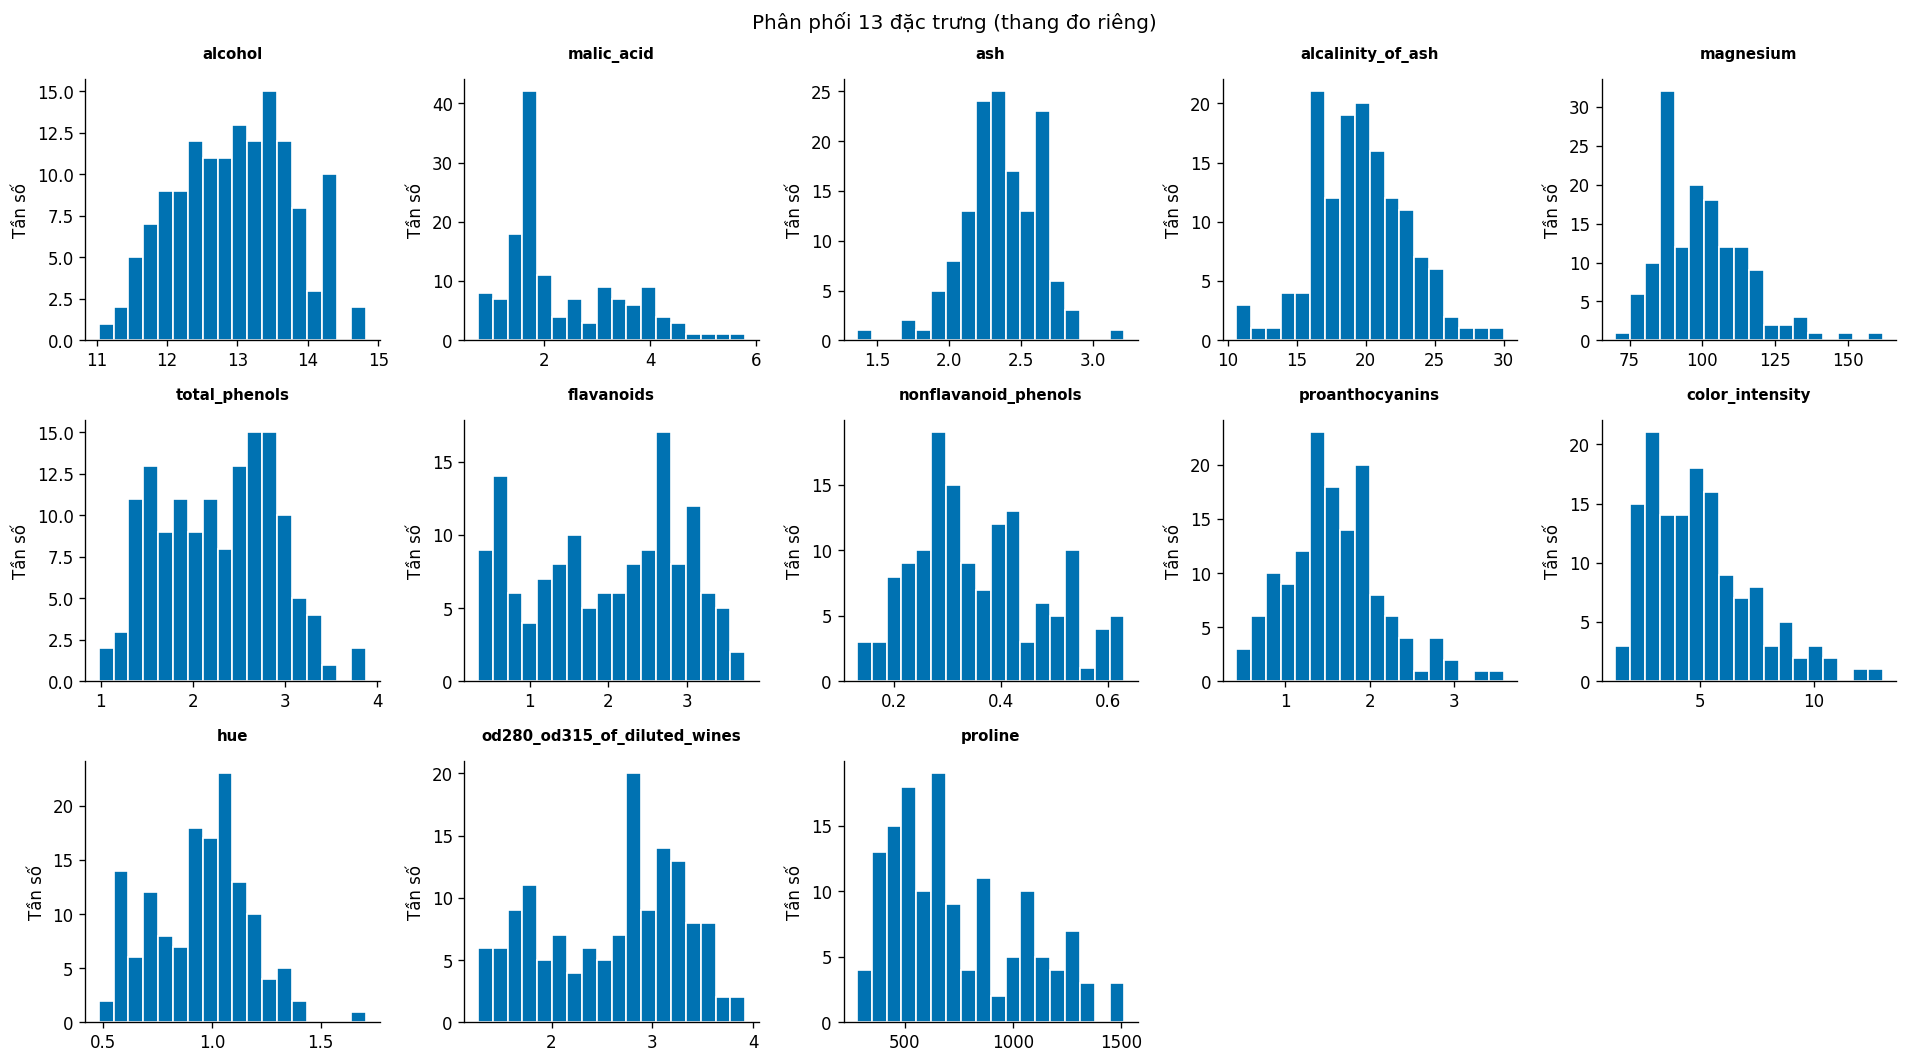

,Skewness (pandas)
magnesium,1.167
malic_acid,0.932
color_intensity,0.924
proline,0.687
proanthocyanins,0.552
nonflavanoid_phenols,0.391
alcalinity_of_ash,0.108
total_phenols,0.087
hue,0.064
alcohol,0.000


**Phân tích.** Biên độ quan sát lớn nhất thuộc **proline** (1237.000), nhỏ nhất thuộc **nonflavanoid_phenols** (0.500), trên các đơn vị đo gốc khác nhau. Đây là khác biệt về thang đo, không phải thứ hạng mức độ quan trọng. Ba thuộc tính có |skewness| lớn nhất là **magnesium: 1.167; malic_acid: 0.932; color_intensity: 0.924**. Giá trị dương biểu thị đuôi phân phối kéo dài về phía giá trị lớn; giá trị âm biểu thị hướng ngược lại. PCA ở phần sau sử dụng dữ liệu chuẩn hóa để hạn chế sự chi phối do thang đo.

WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/05_train_skewness.csv')

In [14]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df_clean[col], bins=18, color="#0072B2", edgecolor="white")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("Tần số")
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Phân phối 13 đặc trưng (thang đo riêng)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "02_train_histograms.png", dpi=200, bbox_inches="tight")
plt.show()
skewness = df_clean[FEATURES].skew().sort_values(ascending=False)
display(skewness.rename("Skewness (pandas)").round(3).to_frame())

ranges = (df_clean[FEATURES].max() - df_clean[FEATURES].min()).sort_values(ascending=False)
skew_rank = skewness.reindex(skewness.abs().sort_values(ascending=False).index).head(3)
skew_text = "; ".join(f"{name}: {value:.3f}" for name, value in skew_rank.items())
display(Markdown(
    f"**Phân tích.** Biên độ quan sát lớn nhất thuộc **{ranges.index[0]}** ({ranges.iloc[0]:.3f}), "
    f"nhỏ nhất thuộc **{ranges.index[-1]}** ({ranges.iloc[-1]:.3f}), trên các đơn vị đo gốc khác nhau. "
    "Đây là khác biệt về thang đo, không phải thứ hạng mức độ quan trọng. "
    f"Ba thuộc tính có |skewness| lớn nhất là **{skew_text}**. "
    "Giá trị dương biểu thị đuôi phân phối kéo dài về phía giá trị lớn; giá trị âm biểu thị hướng ngược lại. "
    "PCA ở phần sau sử dụng dữ liệu chuẩn hóa để hạn chế sự chi phối do thang đo."
))
save_table(skewness.rename("skewness").to_frame(), "05_train_skewness.csv", index=True)

### 1.6. Khảo sát giá trị ngoại lai

Sử dụng ngưỡng Tukey: **[Q1 − 1,5 × IQR; Q3 + 1,5 × IQR]**. Báo cáo riêng số ô bị gắn cờ và số bản ghi có ít nhất một cờ. Boxplot Z-score chỉ phục vụ so sánh phân bố giữa các thuộc tính; không thay đổi dữ liệu nguồn.

**Nguyên tắc xử lý:** điểm ngoài ngưỡng là đối tượng cần xem xét, không mặc nhiên là lỗi. Chưa có thông tin xác minh lỗi đo/nhập liệu nên không loại dòng hoặc cắt ngọn giá trị. Các ngưỡng IQR được tính chỉ từ train và áp dụng nguyên vẹn cho test; diễn giải cùng phân bố theo lớp.

,Q1,Q3,IQR,Số giá trị bị gắn cờ
alcalinity_of_ash,17.200,21.500,4.300,3
magnesium,88.000,107.750,19.750,3
ash,2.200,2.560,0.360,2
proanthocyanins,1.250,1.950,0.700,2
color_intensity,3.058,6.182,3.125,2
malic_acid,1.610,3.170,1.560,1
hue,0.780,1.090,0.310,1
alcohol,12.370,13.560,1.190,0
total_phenols,1.705,2.800,1.095,0
flavanoids,1.228,2.775,1.547,0


Tổng số ô bị gắn cờ: 14
Số dòng có ít nhất một cờ: 11
Quyết định: giữ nguyên các dòng; không cắt ngọn hoặc xóa theo IQR.


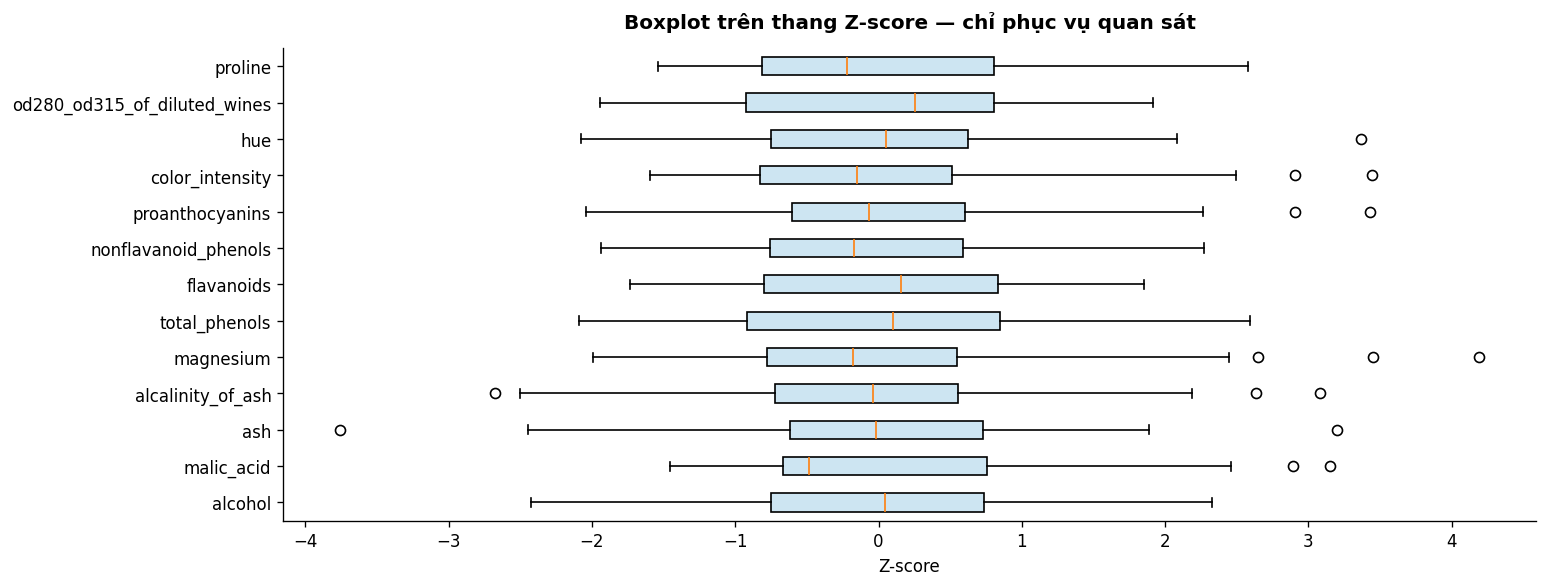

WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/06_train_zscore_for_boxplot.csv')

In [15]:
X = X_train.copy()
y = y_train.copy()
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outlier_mask = X.lt(q1 - 1.5*iqr) | X.gt(q3 + 1.5*iqr)
outlier_summary = pd.DataFrame({"Q1": q1, "Q3": q3, "IQR": iqr,
                                "Số giá trị bị gắn cờ": outlier_mask.sum()})
display(outlier_summary.sort_values("Số giá trị bị gắn cờ", ascending=False).round(3))
print("Tổng số ô bị gắn cờ:", int(outlier_mask.to_numpy().sum()))
print("Số dòng có ít nhất một cờ:", int(outlier_mask.any(axis=1).sum()))
print("Quyết định: giữ nguyên các dòng; không cắt ngọn hoặc xóa theo IQR.")

z_plot = (X - X.mean()) / X.std(ddof=0)
fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot([z_plot[c] for c in FEATURES], vert=False, patch_artist=True,
           boxprops={"facecolor": "#CDE5F2"})
ax.set_yticks(range(1, len(FEATURES)+1), FEATURES)
ax.set(title="Boxplot trên thang Z-score — chỉ phục vụ quan sát", xlabel="Z-score")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "03_train_outlier_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()
# Test dùng ngưỡng IQR của train; chỉ gắn cờ, không loại hoặc sửa giá trị.
test_outlier_mask = X_test.lt(q1 - 1.5*iqr) | X_test.gt(q3 + 1.5*iqr)
save_table(outlier_summary, "06_train_iqr_summary.csv", index=True)
save_table(pd.DataFrame({"lower": q1 - 1.5*iqr, "upper": q3 + 1.5*iqr}), "06_iqr_train_bounds.csv", index=True)
save_table(outlier_mask.astype(int), "06_train_iqr_flags.csv")
save_table(test_outlier_mask.astype(int), "06_test_iqr_flags.csv")
save_table(X_train, "06_X_train_after_outlier_review.csv")
save_table(X_test, "06_X_test_after_outlier_review.csv")
save_table(z_plot, "06_train_zscore_for_boxplot.csv")

In [16]:
flagged_cells = int(outlier_mask.to_numpy().sum())
flagged_rows = int(outlier_mask.any(axis=1).sum())
flag_counts = outlier_mask.sum().sort_values(ascending=False)
flag_text = "; ".join(f"{name}: {int(value)}" for name, value in flag_counts.items() if value > 0)
display(Markdown(
    f"**Phân tích.** Quy tắc IQR gắn cờ **{flagged_cells} giá trị** trên "
    f"**{flagged_rows} bản ghi ({flagged_rows/len(df_clean):.2%})**. "
    f"Phân bố cờ theo thuộc tính: {flag_text or 'không có'}. "
    "Một bản ghi có thể được gắn cờ ở nhiều thuộc tính nên hai số lượng này không tương đương. "
    "Các điểm được giữ lại; kết quả PCA cần được xem xét với lưu ý rằng StandardScaler không loại bỏ ảnh hưởng của ngoại lai."
))

**Phân tích.** Quy tắc IQR gắn cờ **14 giá trị** trên **11 bản ghi (7.75%)**. Phân bố cờ theo thuộc tính: alcalinity_of_ash: 3; magnesium: 3; ash: 2; proanthocyanins: 2; color_intensity: 2; malic_acid: 1; hue: 1. Một bản ghi có thể được gắn cờ ở nhiều thuộc tính nên hai số lượng này không tương đương. Các điểm được giữ lại; kết quả PCA cần được xem xét với lưu ý rằng StandardScaler không loại bỏ ảnh hưởng của ngoại lai.

### 1.7. Mối liên hệ giữa các thuộc tính và phân bố theo lớp

Ma trận Pearson mô tả mức độ liên hệ tuyến tính giữa các thuộc tính liên tục. Mỗi cặp chỉ xuất hiện một lần trong bảng xếp hạng |r|. Tương quan không chứng minh quan hệ nhân quả và không đủ để tự động loại một biến.

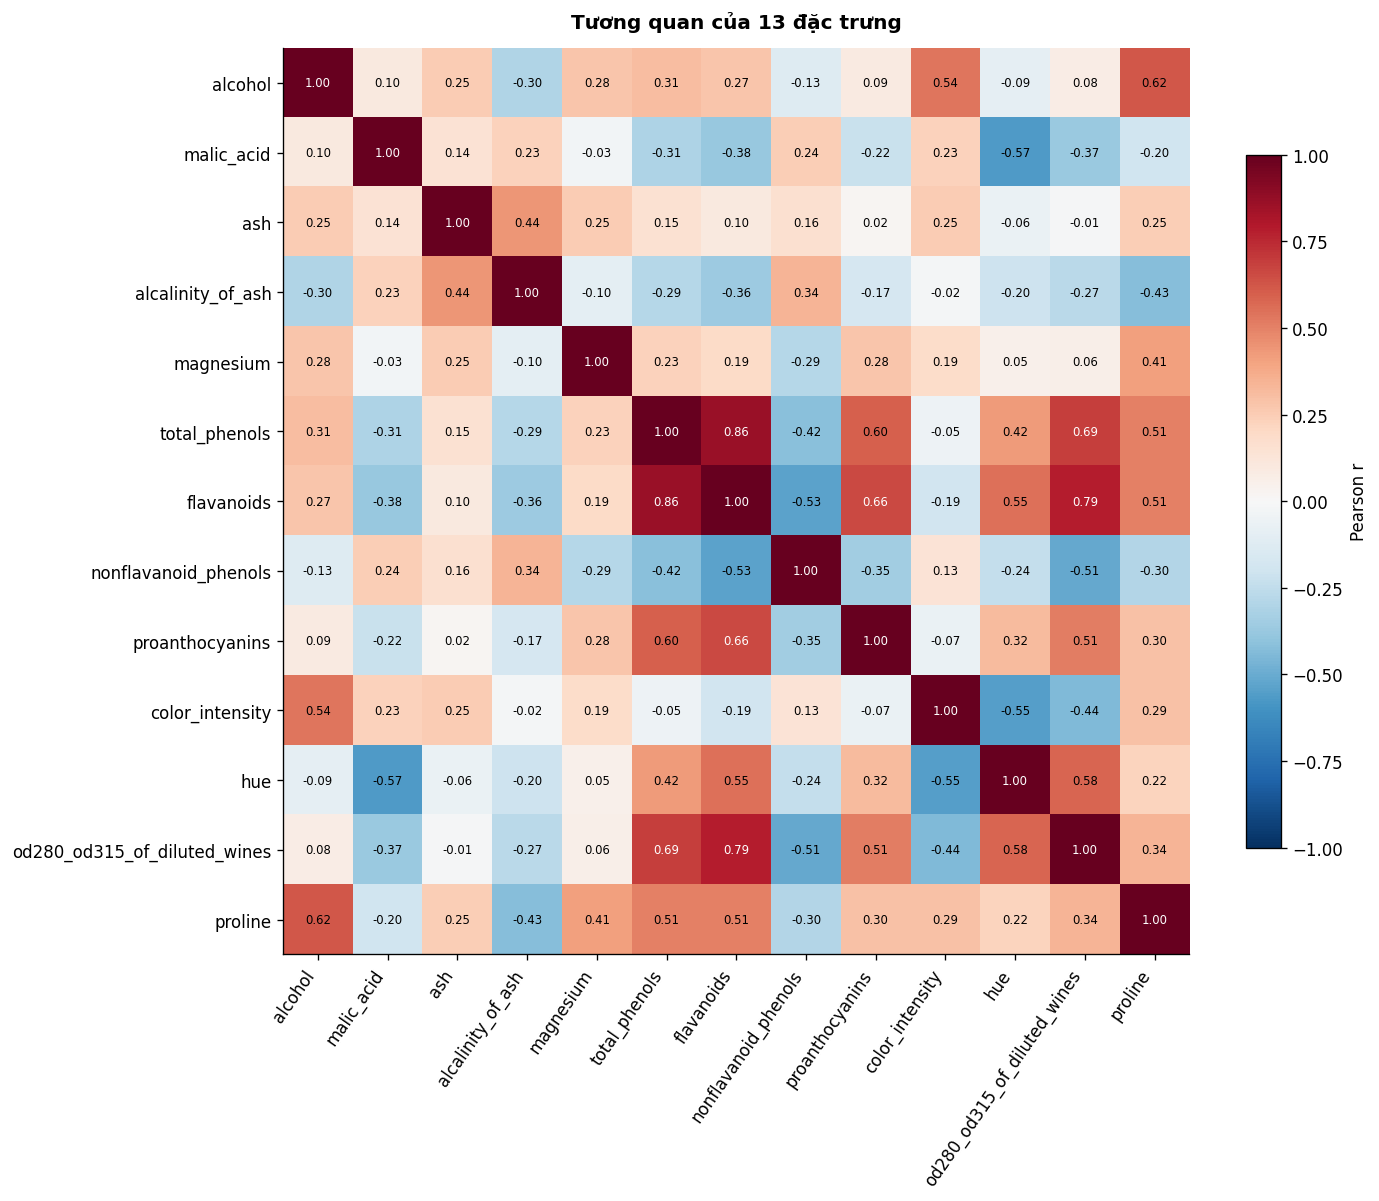

,Đặc trưng A,Đặc trưng B,r
50,total_phenols,flavanoids,0.861
61,flavanoids,od280_od315_of_diluted_wines,0.786
55,total_phenols,od280_od315_of_diluted_wines,0.695
58,flavanoids,proanthocyanins,0.657
11,alcohol,proline,0.621


WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/07_train_top_correlations.csv')

In [17]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=55, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i,j]) > 0.65 else "black")
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("Tương quan của 13 đặc trưng")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "04_train_correlation.png", dpi=200, bbox_inches="tight")
plt.show()
pairs = [(FEATURES[i], FEATURES[j], corr.iloc[i,j])
         for i in range(len(FEATURES)) for j in range(i+1, len(FEATURES))]
top_corr = pd.DataFrame(pairs, columns=["Đặc trưng A", "Đặc trưng B", "r"])
top_corr = top_corr.iloc[np.argsort(-top_corr["r"].abs().to_numpy())].head(5)
display(top_corr.round(3))
save_table(corr, "07_train_correlation.csv", index=True)
save_table(top_corr, "07_train_top_correlations.csv")

In [18]:
strongest = top_corr.iloc[0]
display(Markdown(
    f"**Phân tích tương quan.** Cặp có |r| lớn nhất là **{strongest['Đặc trưng A']}** và "
    f"**{strongest['Đặc trưng B']}**, với **r = {strongest['r']:.3f}** "
    f"({'cùng chiều' if strongest['r'] > 0 else 'ngược chiều'}). "
    "Sự liên hệ giữa các thuộc tính là cơ sở khảo sát khả năng biểu diễn thông tin bằng các thành phần chính. "
    "Chưa loại thuộc tính dựa riêng trên ma trận tương quan."
))

**Phân tích tương quan.** Cặp có |r| lớn nhất là **total_phenols** và **flavanoids**, với **r = 0.861** (cùng chiều). Sự liên hệ giữa các thuộc tính là cơ sở khảo sát khả năng biểu diễn thông tin bằng các thành phần chính. Chưa loại thuộc tính dựa riêng trên ma trận tương quan.

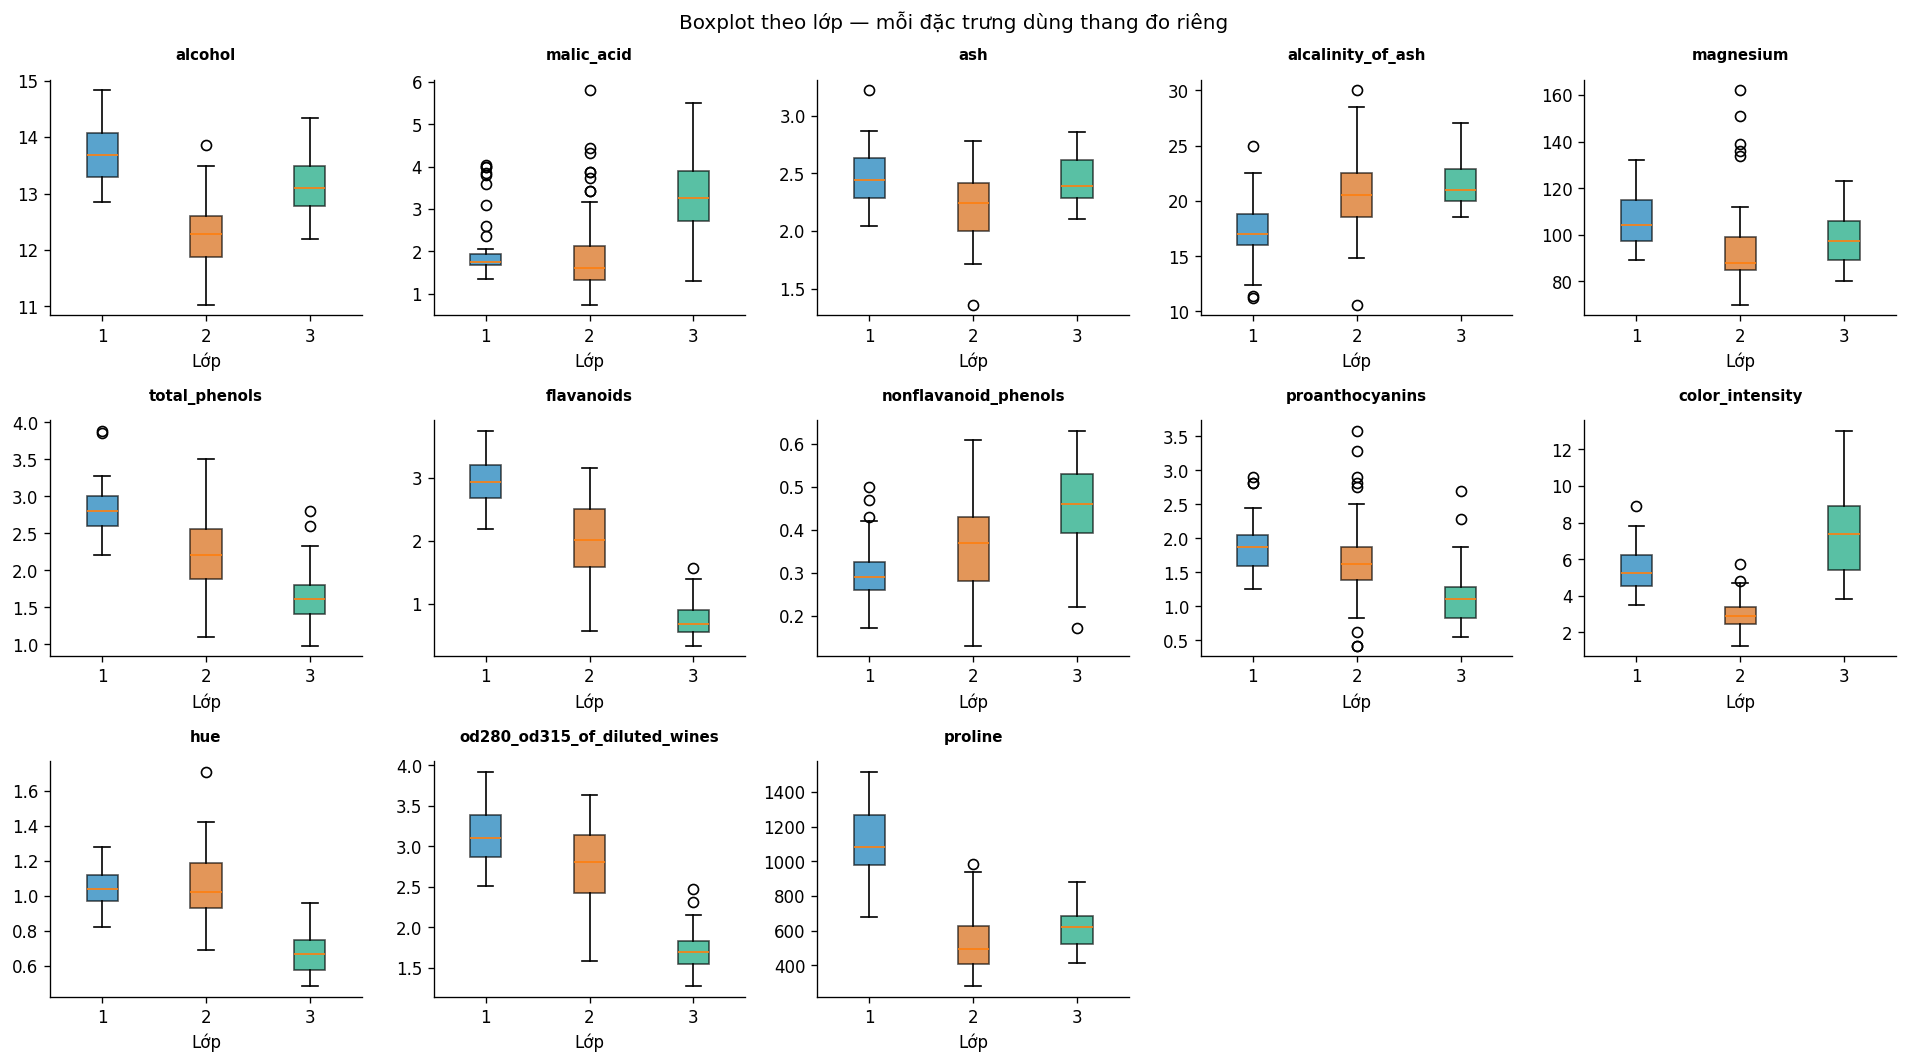

In [19]:
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
classes = sorted(y.unique())
for ax, col in zip(axes.flat, FEATURES):
    bp = ax.boxplot([X.loc[y == k, col] for k in classes], patch_artist=True)
    for box, k in zip(bp["boxes"], classes):
        box.set_facecolor(CLASS_COLORS[k])
        box.set_alpha(0.65)
    ax.set_xticks(range(1, len(classes)+1), [str(k) for k in classes])
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Lớp")
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Boxplot theo lớp — mỗi đặc trưng dùng thang đo riêng")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "05_train_boxplot_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

**Hướng diễn giải boxplot.** So sánh trung vị, độ rộng khoảng tứ phân vị và phần chồng lấn giữa các lớp trong từng thuộc tính. Khác biệt vị trí phân bố cho thấy khả năng phân biệt về mặt mô tả; không được đồng nhất với độ chính xác phân loại. Không so sánh độ cao hộp giữa các thuộc tính có đơn vị khác nhau.

## 2. Tạo dữ liệu mới và trực quan hóa
### 2.1. Chọn thuộc tính liên tục và chuẩn hóa

Chọn các đại lượng đo hóa học làm đầu vào X; tách nhãn y. Giữ Proline vì đây là thuộc tính đo lường, không phải cột dư. Chuẩn hóa theo công thức **z = (x − μ) / σ** để mỗi thuộc tính có trung bình xấp xỉ 0 và độ lệch chuẩn xấp xỉ 1.

Train/test đã được chia trước tiền xử lý. StandardScaler chỉ fit trên X_train; X_test chỉ được transform với trung bình và độ lệch chuẩn của train. PCA cũng chỉ fit trên train và transform test. Mỗi kết quả được lưu riêng. Khi chạy cross-validation sau này, các bước fit vẫn phải được thực hiện lại trong từng fold của Pipeline.

In [20]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)
X_scaled = X_train_scaled  # Các phân tích PCA hiện có chỉ dùng train để fit.

scale_check = pd.DataFrame({"Mean sau chuẩn hóa": X_train_scaled.mean(),
                           "Std sau chuẩn hóa (ddof=0)": X_train_scaled.std(ddof=0)})
display(scale_check.round(6))
assert TARGET not in X_train_scaled.columns and TARGET not in X_test_scaled.columns
assert np.isfinite(X_train_scaled.to_numpy()).all() and np.isfinite(X_test_scaled.to_numpy()).all()
assert np.allclose(X_train_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_train_scaled.std(ddof=0), 1, atol=1e-10)

# x_train/x_test là các đặc trưng chuẩn hóa, không chứa nhãn.
save_table(X_train_scaled, "x_train.csv")
save_table(X_test_scaled, "x_test.csv")
save_table(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=FEATURES),
           "08_scaler_train_parameters.csv", index=True)
save_table(scale_check, "08_train_scaling_check.csv", index=True)
print("Đã lưu x_train.csv và x_test.csv; nhãn nằm riêng trong y_train.csv, y_test.csv.")

,Mean sau chuẩn hóa,Std sau chuẩn hóa (ddof=0)
alcohol,0.0,1.0
malic_acid,0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,0.0,1.0
magnesium,0.0,1.0
total_phenols,-0.0,1.0
flavanoids,-0.0,1.0
nonflavanoid_phenols,-0.0,1.0
proanthocyanins,0.0,1.0
color_intensity,0.0,1.0


Đã lưu x_train.csv và x_test.csv; nhãn nằm riêng trong y_train.csv, y_test.csv.


### 2.2. Phương sai giải thích và giới hạn của biểu diễn 2D

PCA xác định các trục trực giao theo phương sai của dữ liệu đã chuẩn hóa, không sử dụng nhãn. Báo cáo phương sai từng thành phần và phương sai tích lũy để lượng hóa thông tin được giữ lại. Ngưỡng 95% là thông tin bổ sung; yêu cầu trực quan hóa vẫn sử dụng hai thành phần đầu.

Tỷ lệ phương sai báo cáo được tính trên train. Test không tham gia xác định các trục hoặc số thành phần chính.

,PC,Phương sai (%),Tích lũy (%)
0,1,35.79,35.79
1,2,19.27,55.06
2,3,11.02,66.08
3,4,7.27,73.35
4,5,6.72,80.08
5,6,5.13,85.21
6,7,4.38,89.59
7,8,2.50,92.09
8,9,2.28,94.37
9,10,1.88,96.24


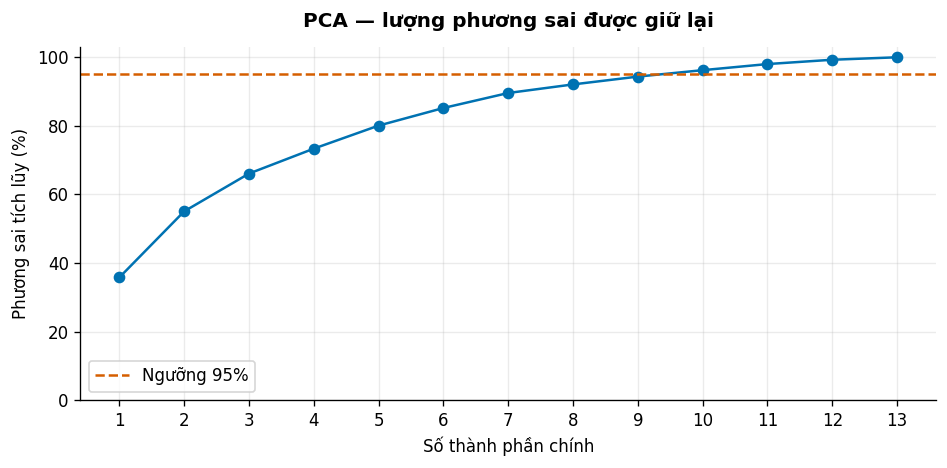

Hai PC đầu giữ 55.06% phương sai.
Cần 10 PC để giữ ít nhất 95% (thực tế: 96.24%).


WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/09_X_test_pca95.csv')

In [21]:
pca_full = PCA(svd_solver="full")
pca_full.fit(X_scaled)
ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratio)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
variance_table = pd.DataFrame({"PC": np.arange(1, len(ratio)+1),
                               "Phương sai (%)": ratio*100,
                               "Tích lũy (%)": cumulative*100})
display(variance_table.round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(variance_table["PC"], cumulative*100, "o-", color="#0072B2")
ax.axhline(95, color="#D55E00", linestyle="--", label="Ngưỡng 95%")
ax.set(xlabel="Số thành phần chính", ylabel="Phương sai tích lũy (%)",
       title="PCA — lượng phương sai được giữ lại", xticks=range(1, len(ratio)+1), ylim=(0,103))
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "06_train_pca_variance.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Hai PC đầu giữ {cumulative[1]:.2%} phương sai.")
print(f"Cần {n95} PC để giữ ít nhất 95% (thực tế: {cumulative[n95-1]:.2%}).")
save_table(variance_table, "09_pca_train_explained_variance.csv")
all_pc_names = [f"PC{i+1}" for i in range(len(ratio))]
train_all_pc = pd.DataFrame(pca_full.transform(X_train_scaled), columns=all_pc_names, index=X_train.index)
test_all_pc = pd.DataFrame(pca_full.transform(X_test_scaled), columns=all_pc_names, index=X_test.index)
save_table(train_all_pc, "09_X_train_pca_all.csv")
save_table(test_all_pc, "09_X_test_pca_all.csv")
save_table(train_all_pc.iloc[:, :n95], "09_X_train_pca95.csv")
save_table(test_all_pc.iloc[:, :n95], "09_X_test_pca95.csv")

### 2.3. Biểu diễn PCA hai chiều theo nhãn

Tạo bảng mới gồm PC1, PC2 và nhãn để diễn giải. Các nhãn được gắn lại sau phép biến đổi, không tham gia fit PCA. Biểu đồ sử dụng màu lớp thống nhất, hiển thị tỷ lệ phương sai ngay trên từng trục.

Biểu đồ giữ nguyên bố cục và hiển thị train. Dữ liệu test được chiếu bằng cùng PCA và lưu riêng, không gộp với train.

,PC1,PC2,class
36,1.472343,0.734251,1
30,2.649709,1.230211,1
26,1.888788,0.792472,1
12,2.211159,0.753458,1
148,-2.817571,1.645688,3
171,-3.731651,0.943745,3
69,2.003185,-1.488667,2
150,-2.287491,2.379894,3
53,2.344948,1.926216,1
8,2.583804,1.010108,1


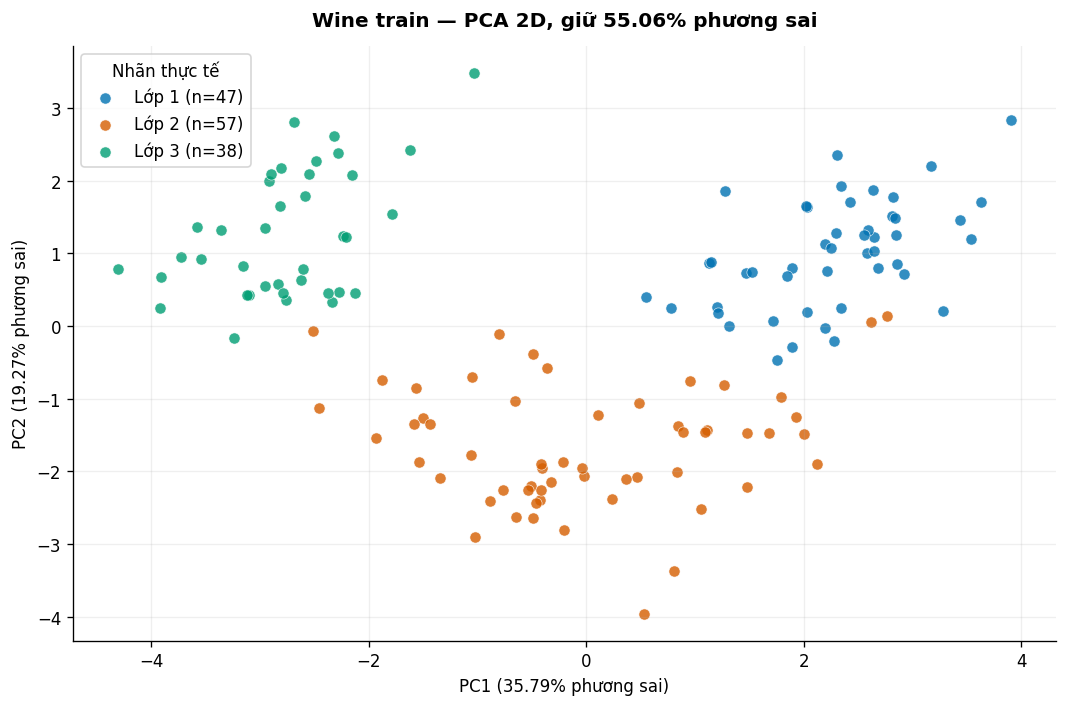

**Đánh giá phép chiếu.** PC1 giải thích **35.79%**, PC2 giải thích **19.27%**, tổng cộng **55.06%** phương sai. **44.94%** phương sai còn lại nằm ở các chiều không được thể hiện trên hình. Vì vậy, các điểm gần nhau trong 2D không nhất thiết gần nhau tương ứng trong toàn bộ không gian đặc trưng. Màu thể hiện nhãn quan sát, không phải cụm do PCA tìm ra. PCA tối đa hóa phương sai thay vì tối ưu độ tách lớp; không suy ra hiệu năng phân loại từ hình chiếu.

In [22]:
pca_2d = PCA(n_components=2, svd_solver="full")
coordinates = pca_2d.fit_transform(X_train_scaled)
test_coordinates = pca_2d.transform(X_test_scaled)
X_train_pca = pd.DataFrame(coordinates, columns=["PC1", "PC2"], index=X_train.index)
X_test_pca = pd.DataFrame(test_coordinates, columns=["PC1", "PC2"], index=X_test.index)
save_table(X_train_pca, "10_X_train_pca2d.csv")
save_table(X_test_pca, "10_X_test_pca2d.csv")
train_pca_labeled = X_train_pca.assign(**{TARGET: y_train})
test_pca_labeled = X_test_pca.assign(**{TARGET: y_test})
save_table(train_pca_labeled, "10_train_pca2d_with_label.csv")
save_table(test_pca_labeled, "10_test_pca2d_with_label.csv")
df_pca_2d = pd.DataFrame(coordinates, columns=["PC1", "PC2"], index=X.index)
df_pca_2d["class"] = y
display(df_pca_2d.head(10))
fig, ax = plt.subplots(figsize=(9, 6))
for k in classes:
    group = df_pca_2d.loc[df_pca_2d["class"] == k]
    ax.scatter(group["PC1"], group["PC2"], color=CLASS_COLORS[k],
               label=f"Lớp {k} (n={len(group)})", s=45, alpha=0.8,
               edgecolors="white", linewidths=0.4)
v1, v2 = pca_2d.explained_variance_ratio_
ax.set(xlabel=f"PC1 ({v1:.2%} phương sai)", ylabel=f"PC2 ({v2:.2%} phương sai)",
       title=f"Wine train — PCA 2D, giữ {v1+v2:.2%} phương sai")
ax.legend(title="Nhãn thực tế")
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "07_train_pca2d.png", dpi=200, bbox_inches="tight")
plt.show()

display(Markdown(
    f"**Đánh giá phép chiếu.** PC1 giải thích **{v1:.2%}**, PC2 giải thích **{v2:.2%}**, "
    f"tổng cộng **{v1+v2:.2%}** phương sai. **{1-v1-v2:.2%}** phương sai còn lại nằm ở các chiều "
    "không được thể hiện trên hình. Vì vậy, các điểm gần nhau trong 2D không nhất thiết gần nhau tương ứng "
    "trong toàn bộ không gian đặc trưng. Màu thể hiện nhãn quan sát, không phải cụm do PCA tìm ra. "
    "PCA tối đa hóa phương sai thay vì tối ưu độ tách lớp; không suy ra hiệu năng phân loại từ hình chiếu."
))

### 2.4. Diễn giải các thành phần chính

Bảng dưới trình bày hệ số của các thuộc tính trong PC1 và PC2 trên dữ liệu chuẩn hóa. Giá trị tuyệt đối lớn biểu thị trọng số lớn trong tổ hợp tuyến tính; không phải độ quan trọng của một mô hình phân loại. Dấu toàn bộ một trục PCA có thể đảo mà không làm thay đổi cấu trúc phép chiếu.

In [23]:
coefficients = pd.DataFrame(pca_2d.components_.T, index=FEATURES, columns=["PC1", "PC2"])
display(coefficients.round(4))
for component in coefficients.columns:
    ordered = coefficients[component].abs().nlargest(3).index
    terms = "; ".join(f"{name} ({coefficients.loc[name, component]:+.3f})" for name in ordered)
    display(Markdown(f"**{component}:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: {terms}."))
save_table(coefficients, "10_pca2d_train_coefficients.csv", index=True)

,PC1,PC2
alcohol,0.1444,0.4869
malic_acid,-0.2337,0.2229
ash,0.0071,0.3116
alcalinity_of_ash,-0.2236,-0.0390
magnesium,0.1518,0.2964
total_phenols,0.3944,0.0763
flavanoids,0.4295,-0.0025
nonflavanoid_phenols,-0.2914,0.0208
proanthocyanins,0.3133,0.0109
color_intensity,-0.0964,0.5244


**PC1:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: flavanoids (+0.430); total_phenols (+0.394); od280_od315_of_diluted_wines (+0.383).

**PC2:** ba thuộc tính có hệ số lớn nhất về trị tuyệt đối: color_intensity (+0.524); alcohol (+0.487); proline (+0.358).

WindowsPath('D:/k1_nam3/data_mining/data_mining/datasets/output/10_pca2d_train_coefficients.csv')

### 2.5. Dữ liệu đầu ra

Mỗi bước đã lưu ngay vào tệp CSV riêng trong `datasets/output`. `train_data.csv` và `test_data.csv` là dữ liệu sau chia, trước xử lý; `x_train.csv` và `x_test.csv` là đặc trưng sau chuẩn hóa, không chứa nhãn. Nhãn nằm trong `y_train.csv`, `y_test.csv`; thứ tự dòng khớp với các tệp X của cùng tập sau làm sạch. Các tệp PCA được lưu riêng, không ghi đè các tệp chuẩn hóa. Bảng bên dưới liệt kê đầy đủ các tệp tạo trong lần chạy.

Biểu đồ PNG được lưu vào thư mục `output` ở gốc dự án. Không tạo thư mục `wine_preprocessing_output` mới và không gộp train/test vào một tệp.

In [24]:
assert len(X_train_scaled) == len(y_train) == len(X_train_pca)
assert len(X_test_scaled) == len(y_test) == len(X_test_pca)
assert X_train_scaled.index.equals(y_train.index)
assert X_test_scaled.index.equals(y_test.index)
assert np.isfinite(test_coordinates).all()

manifest = pd.DataFrame(saved_files).drop_duplicates("Tệp", keep="last").reset_index(drop=True)
display(manifest)
manifest.to_csv(OUTPUT_DIR / "output_manifest.csv", index=False, encoding="utf-8-sig")
print("CSV:", OUTPUT_DIR)
print("Biểu đồ PNG:", FIGURE_DIR)

,Tệp,Số dòng,Thư mục
0,00_wine_from_xlsx.csv,178,datasets/output
1,train_data.csv,142,datasets/output
2,test_data.csv,36,datasets/output
3,01_split_membership.csv,178,datasets/output
4,02_train_columns_cleaned.csv,142,datasets/output
5,02_test_columns_cleaned.csv,36,datasets/output
6,03_train_dtypes.csv,14,datasets/output
7,03_train_class_counts.csv,3,datasets/output
8,03_train_quality.csv,14,datasets/output
9,04_train_clean.csv,142,datasets/output


CSV: D:\k1_nam3\data_mining\data_mining\datasets\output
Biểu đồ PNG: D:\k1_nam3\data_mining\data_mining\datasets\output


## Kết luận phân tích

Tóm tắt dưới đây được sinh từ kết quả xử lý hiện tại. Mọi thay đổi về tệp nguồn cần được phản ánh bằng cách chạy lại toàn bộ notebook.

In [25]:
summary = f"""
| Nội dung | Kết quả |
|---|---|
| Quy mô train dùng phân tích | {len(df_clean):,} mẫu × {len(FEATURES)} đặc trưng; {y.nunique()} lớp |
| Giá trị thiếu / không phải số / vô hạn | {int(quality['Thiếu'].sum())} / {int(quality['Không phải số'].sum())} / {int(quality['Vô hạn'].sum())} |
| Quy mô test sau làm sạch | {len(test_clean):,} mẫu |
| Bản ghi trùng đã loại (train / test) | {duplicate_count} / {test_duplicate_count} |
| Bản ghi có cờ IQR | {flagged_rows} ({flagged_rows/len(df_clean):.2%}); giữ nguyên để phân tích |
| Phương sai giữ lại trong 2D | {v1+v2:.2%} |
| Phương sai ngoài biểu diễn 2D | {1-v1-v2:.2%} |
| Số PC đạt ít nhất 95% phương sai | {n95} ({cumulative[n95-1]:.2%}) |

**Kết luận.** Quy trình đã chia train/test trước xử lý, fit scaler và PCA chỉ trên train, lưu riêng kết quả từng bước, xác nhận cấu trúc dữ liệu, báo cáo thống kê thuộc tính và phân bố nhãn, khảo sát chất lượng và tạo biểu diễn PCA hai chiều. Chuẩn hóa xử lý chênh lệch thang đo, còn bảng hệ số giúp giải thích vai trò của các thuộc tính trong hai trục chính. Hình chiếu chỉ thể hiện một phần phương sai; cần giữ bảng đặc trưng gốc khi thực hiện các phân tích tiếp theo. Không loại thuộc tính hoặc bản ghi chỉ dựa vào tương quan, cờ IQR hay vị trí điểm trên hình PCA.
"""
display(Markdown(summary))


| Nội dung | Kết quả |
|---|---|
| Quy mô train dùng phân tích | 142 mẫu × 13 đặc trưng; 3 lớp |
| Giá trị thiếu / không phải số / vô hạn | 0 / 0 / 0 |
| Quy mô test sau làm sạch | 36 mẫu |
| Bản ghi trùng đã loại (train / test) | 0 / 0 |
| Bản ghi có cờ IQR | 11 (7.75%); giữ nguyên để phân tích |
| Phương sai giữ lại trong 2D | 55.06% |
| Phương sai ngoài biểu diễn 2D | 44.94% |
| Số PC đạt ít nhất 95% phương sai | 10 (96.24%) |

**Kết luận.** Quy trình đã chia train/test trước xử lý, fit scaler và PCA chỉ trên train, lưu riêng kết quả từng bước, xác nhận cấu trúc dữ liệu, báo cáo thống kê thuộc tính và phân bố nhãn, khảo sát chất lượng và tạo biểu diễn PCA hai chiều. Chuẩn hóa xử lý chênh lệch thang đo, còn bảng hệ số giúp giải thích vai trò của các thuộc tính trong hai trục chính. Hình chiếu chỉ thể hiện một phần phương sai; cần giữ bảng đặc trưng gốc khi thực hiện các phân tích tiếp theo. Không loại thuộc tính hoặc bản ghi chỉ dựa vào tương quan, cờ IQR hay vị trí điểm trên hình PCA.
